# Diabetic Retinopathy Grading on the Edge
IESTI05 — Edge AI Engineering · Part 1 Final Project

By Mirela Domiciano @2026

## Setup

### GPU and Drive

In [1]:
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')

/bin/bash: line 1: nvidia-smi: command not found
Mounted at /content/drive


### Dependencies and Versions

In [2]:
!pip install -q imagehash
import tensorflow as tf, numpy as np, pandas as pd, sklearn
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices('GPU'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 3.4 MB/s eta 0:00:00
TF 2.21.0 | GPU: []


### Kaggle Credencials

In [3]:
!pip install -q -U kaggle
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN_TCC")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 1.2 MB/s eta 0:00:00


### Settings and Seed

In [4]:
from pathlib import Path

# control painel
CFG = dict(seed=42, model="mobilenetv2", data="aptos", img_size=384,
           batch=32, epochs_head=5, epochs_ft=30, lr_head=1e-3, lr_ft=1e-4,
           class_weight="sqrt")

# dir
DRIVE = Path("/content/drive/MyDrive/tcc"); DATA = Path("/content/data")
for p in [DRIVE / "raw", DRIVE / "runs", DATA]: p.mkdir(parents=True, exist_ok=True)

# seed
SEED = CFG["seed"]
tf.keras.utils.set_random_seed(SEED)

## Dataset Download

### Download and Extraction

Only the first time

In [5]:
small_zip = DRIVE / "raw" / "aptos_512.zip"
if not small_zip.exists():
    !kaggle competitions download -c aptos2019-blindness-detection -p /content
    !unzip -q -o /content/aptos2019-blindness-detection.zip "train.csv" "train_images/*" -d /content/aptos_orig
    !rm /content/aptos2019-blindness-detection.zip

### Resize and Save

Only the first time

In [6]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
src, dst = Path("/content/aptos_orig"), DATA / "aptos"
def resize(p):
    with Image.open(p) as im:
        im.thumbnail((512, 512)); im.save(dst / "train_images" / p.name)
if not small_zip.exists():
    (dst / "train_images").mkdir(parents=True, exist_ok=True)
    with ThreadPoolExecutor(8) as ex: list(ex.map(resize, (src / "train_images").glob("*.png")))
    !cp {src}/train.csv {dst}/ && cd {DATA} && zip -qr {small_zip} aptos

### Prepare Data

In [7]:
if not (DATA / "aptos").exists():
    !unzip -q -o {small_zip} -d {DATA}
print(len(list((DATA / "aptos" / "train_images").glob("*.png"))), "imagens")

3662 imagens


## Deduplication and Stratified Split

APTOS has known duplicates and near-duplicates in the community, some with **different grades assigned to the same image**. If a duplicate ends up in train and another copy in test, the model is evaluated on something it has already seen (data leakage), which inflates accuracy and QWK without reflecting real learning.

This matters especially here because the intra-domain ceiling from this experiment is the baseline later used in the thesis to measure the cross-domain drop. An inflated ceiling from leakage makes the drop look larger than it really is.

Process:
- An exact hash (MD5) catches identical copies;
- A perceptual hash (pHash) catches near-duplicates (same image with slight cropping, compression, or brightness differences);
- For each near-duplicate pair, if the two images have conflicting labels, both are removed (unreliable ground truth); otherwise, one copy is kept. The split is then stratified by class **and** by dataset origin.

### Functions Load

In [8]:
%run /content/drive/MyDrive/tcc/scripts/dedup_split.py

### Run Cleanup

In [9]:
# Hashing: MD5 identifies exact copies; pHash catches near-duplicates.
df = compute_hashes(load_sources(), OUT_DIR)
pairs = near_pairs(df, max_dist=10)   # calcula uma vez, com folga
pairs["dist"].value_counts().sort_index()

[cache] hashes reaproveitados (hashes_crop_8.csv)


comparando:   0%|          | 0/3661 [00:00<?, ?it/s]

,count
dist,
0,160
2,289
4,1842
6,6745
8,17884
10,37480


### Visual inspection

pHash on fundus photos is less discriminative than usual: patients share the same composition (optic disc position, macula, camera mask shape), and the 64-bit hash mostly captures that composition rather than the vessel pattern that actually distinguishes patients. So pairs at low distances can still be different people, not just the same image edited.

Inspect pairs distance by distance, starting from 0, before fixing `PHASH_THRESH`:

```python
show_near_pairs(df, pairs, dist=0, n=8)
show_near_pairs(df, pairs, dist=2, n=8)
```

- Pairs that are clearly the same photo (even if resized, recompressed, or recolored) → that distance is safe to include
- Pairs that look like different patients → that distance is already too loose; stop increasing `PHASH_THRESH` before it

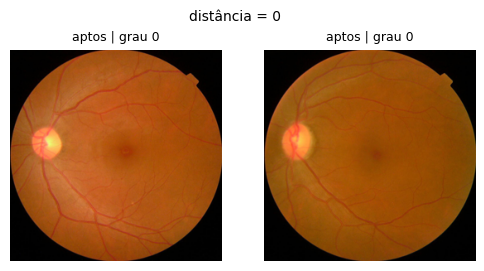

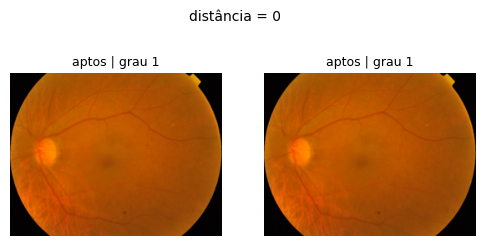

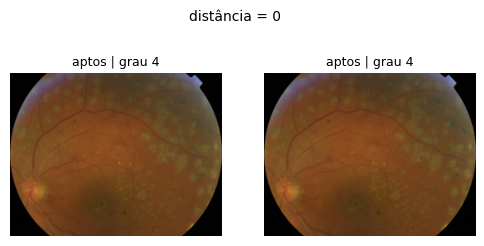

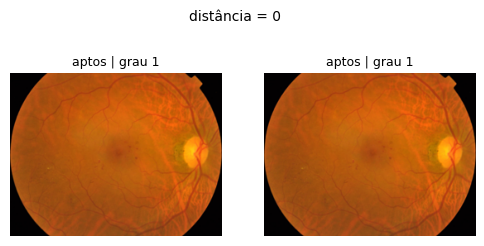

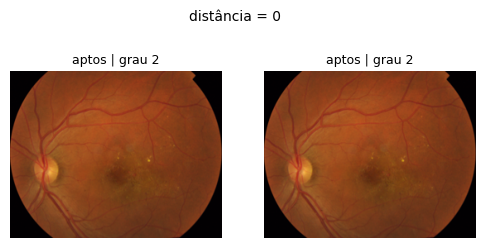

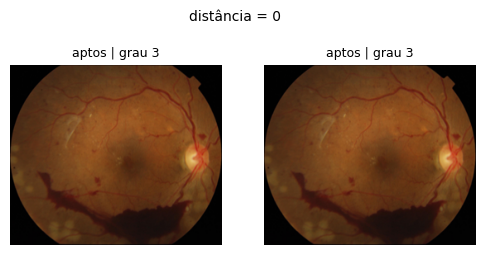

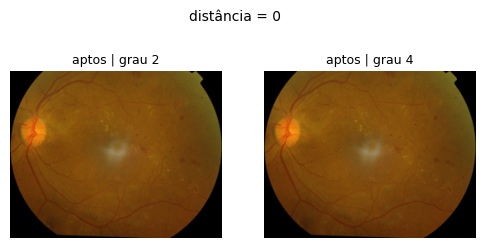

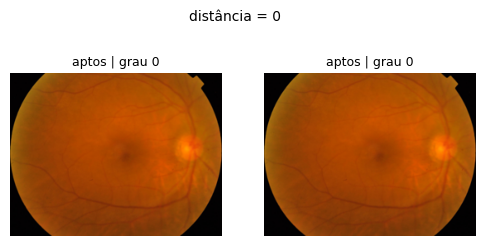

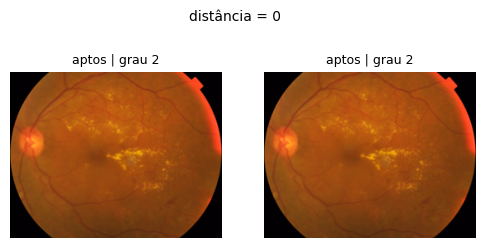

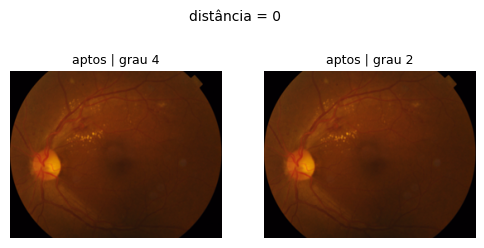

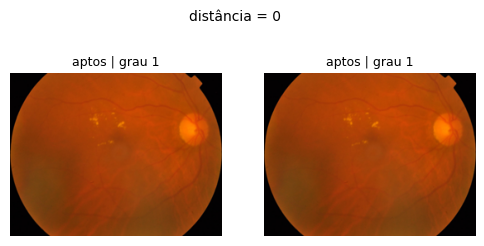

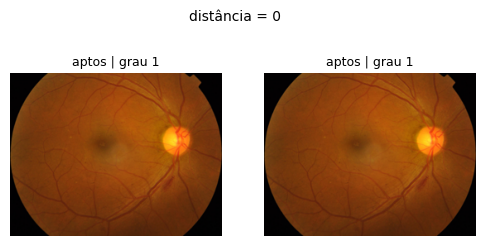

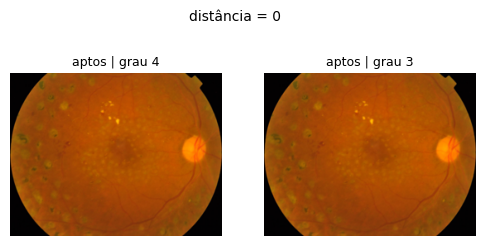

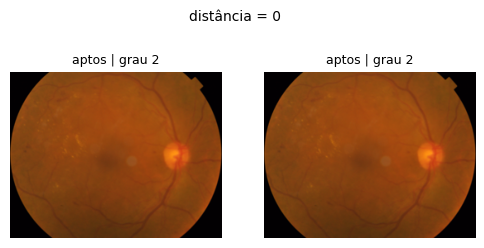

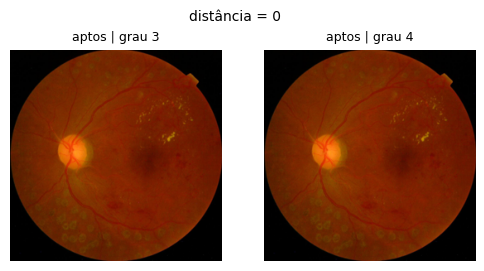

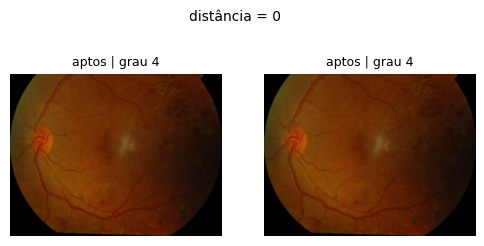

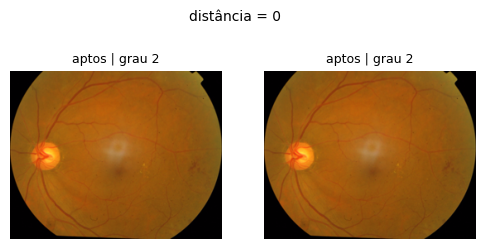

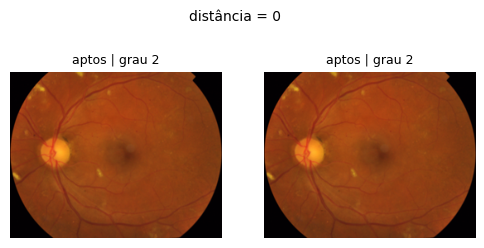

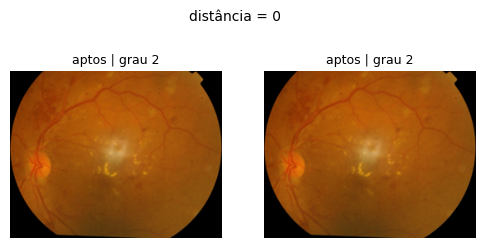

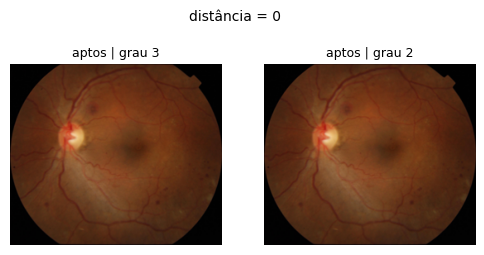

In [10]:
show_near_pairs(df, pairs, dist=0, n=20)

### Deduplication and Split

In [11]:
PHASH_THRESH = 0
clean, report = deduplicate(df, pairs[pairs["dist"] <= PHASH_THRESH])
for k, v in report.items(): print(f"{k}: {v}")

splits = stratified_split(clean)
splits.drop(columns=["md5", "phash_hex"]).to_csv(OUT_DIR / "splits.csv", index=False)
pd.Series(report).to_csv(OUT_DIR / "dedup_report.csv")
print(pd.crosstab([splits["source"], splits["split"]], splits["label"], margins=True))

imagens: 3662
duplicatas exatas (md5): 128
pares de quase-duplicatas: 160
pares com rótulo conflitante: 42
imagens removidas por rótulo conflitante: 77
imagens removidas como duplicata: 108
imagens finais: 3477
label            0    1    2    3    4   All
source split                                
aptos  test    268   51  138   25   40   522
       train  1249  237  644  118  185  2433
       val     268   50  139   25   40   522
All           1785  338  921  168  265  3477


### Deduplication evidence

Saves every removed pair to CSV (traceability) and a figure with a few examples for the report. Conflicting pairs (same image, different grades) are evidence of label noise in APTOS — relevant to interpret the model's accuracy ceiling.

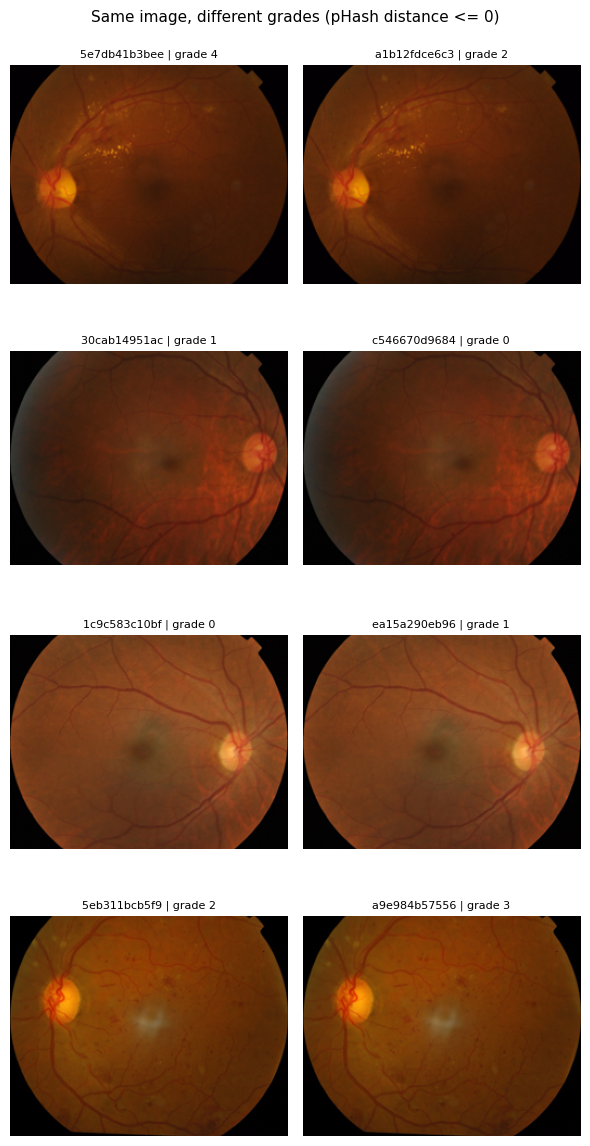

conflicting_pairs: 42 pairs -> /content/drive/MyDrive/tcc/data/evidence/conflicting_pairs.csv / .png


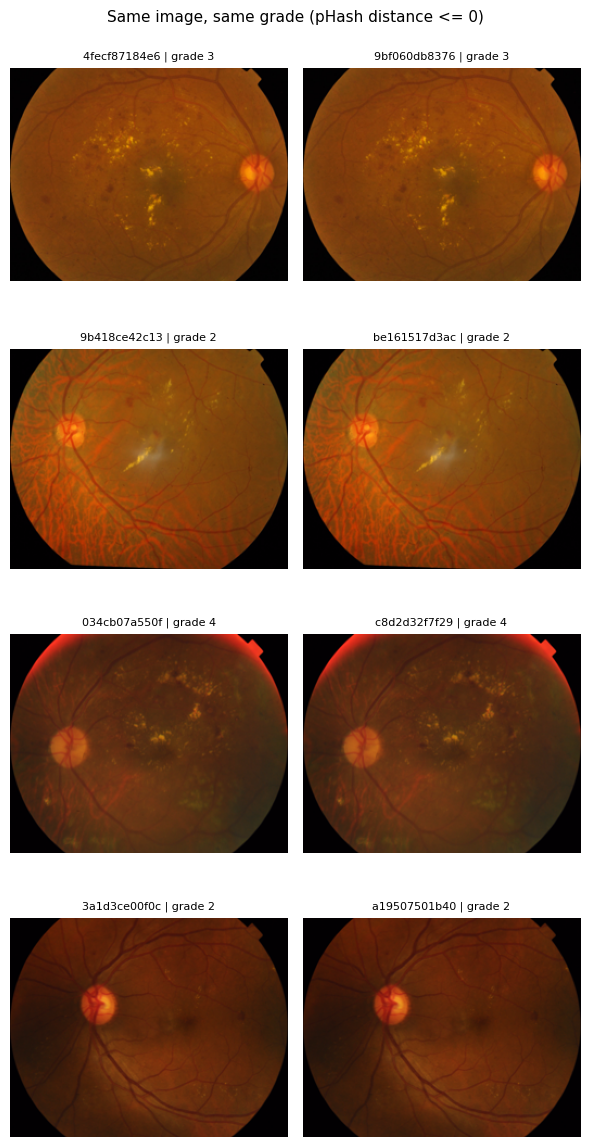

duplicate_pairs: 118 pairs -> /content/drive/MyDrive/tcc/data/evidence/duplicate_pairs.csv / .png


In [12]:
import matplotlib.pyplot as plt

EVIDENCE_DIR = OUT_DIR / "evidence"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
N_EXAMPLES = 4

dup_pairs = pairs[pairs["dist"] <= PHASH_THRESH]
labels = df["label"].to_numpy()
is_conflict = labels[dup_pairs["i"].to_numpy()] != labels[dup_pairs["j"].to_numpy()]

for name, sel, title in [
    ("conflicting_pairs", dup_pairs[is_conflict], "Same image, different grades"),
    ("duplicate_pairs", dup_pairs[~is_conflict], "Same image, same grade"),
]:
    # CSV with every pair (traceability of what was removed)
    rec_i, rec_j = df.iloc[sel["i"]].reset_index(drop=True), df.iloc[sel["j"]].reset_index(drop=True)
    pd.DataFrame({
        "image_i": rec_i["path"].map(lambda p: Path(p).stem), "source_i": rec_i["source"], "grade_i": rec_i["label"],
        "image_j": rec_j["path"].map(lambda p: Path(p).stem), "source_j": rec_j["source"], "grade_j": rec_j["label"],
        "dist": sel["dist"].to_numpy(),
    }).to_csv(EVIDENCE_DIR / f"{name}.csv", index=False)

    # Figure with a few examples for the report
    if sel.empty:
        print(f"{name}: no pairs"); continue
    shown = sel.sample(min(N_EXAMPLES, len(sel)), random_state=SEED)
    fig, axes = plt.subplots(len(shown), 2, figsize=(6, 3 * len(shown)), squeeze=False)
    for row_axes, (_, r) in zip(axes, shown.iterrows()):
        for ax, k in zip(row_axes, (int(r["i"]), int(r["j"]))):
            rec = df.iloc[k]
            with Image.open(rec["path"]) as im:
                ax.imshow(_display(im))
            ax.set_title(f"{Path(rec['path']).stem} | grade {rec['label']}", fontsize=8)
            ax.axis("off")
    fig.suptitle(f"{title} (pHash distance <= {PHASH_THRESH})", fontsize=11)
    fig.tight_layout()
    fig.savefig(EVIDENCE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"{name}: {len(sel)} pairs -> {EVIDENCE_DIR / name}.csv / .png")

## Dataset Summary

Confirms that the cleaned dataset is ready for training: files saved to Drive,
class balance per split, and the distribution figure required by the assignment ("dataset statistics and visualization").

### File Check

In [13]:
for f in ["splits.csv", "dedup_report.csv", "evidence/conflicting_pairs.csv", "evidence/duplicate_pairs.csv"]:
    p = OUT_DIR / f
    print(f"{'OK ' if p.exists() else 'FALTA'} {p}")

OK  /content/drive/MyDrive/tcc/data/splits.csv
OK  /content/drive/MyDrive/tcc/data/dedup_report.csv
OK  /content/drive/MyDrive/tcc/data/evidence/conflicting_pairs.csv
OK  /content/drive/MyDrive/tcc/data/evidence/duplicate_pairs.csv


### Class Balance

Grades 3 and 4 (severe and proliferative) are the rarest in APTOS. After splitting and deduplication, their count in val/test can get small enough that per-class metrics (e.g. grade 4 sensitivity) become noisy across runs — worth knowing before interpreting results later.

In [14]:
counts = splits.groupby(["split", "label"]).size().unstack(fill_value=0)
print(counts)

low = counts.loc[["val", "test"], [3, 4]]
if (low < 20).any().any():
    print("\n[atenção] grau(s) com menos de 20 imagens em val ou test:")
    print(low[low < 20].dropna(how="all", axis=1).dropna(how="all"))
else:
    print("\nOK: graus 3 e 4 têm pelo menos 20 imagens em val e test")

label     0    1    2    3    4
split                          
test    268   51  138   25   40
train  1249  237  644  118  185
val     268   50  139   25   40

OK: graus 3 e 4 têm pelo menos 20 imagens em val e test


### Class Distribution Plot

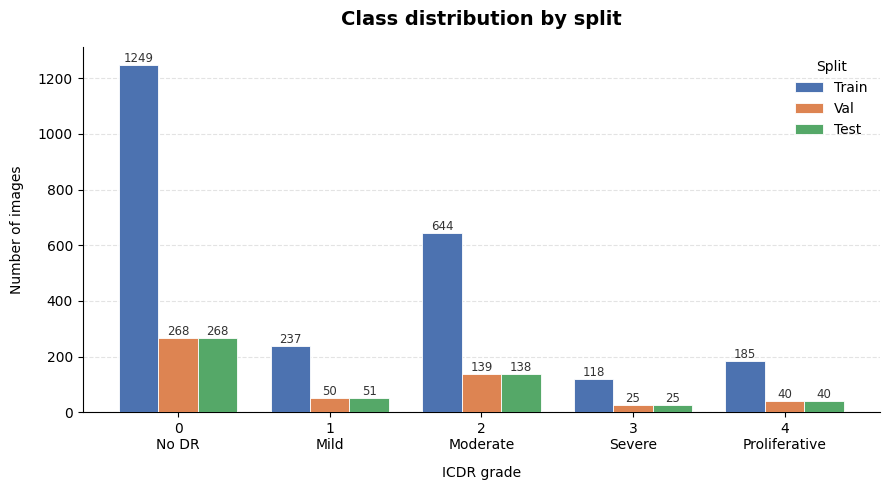

In [15]:
import numpy as np
import matplotlib.pyplot as plt

counts = counts.reindex(columns=range(5), fill_value=0)  # garante as 5 colunas na ordem certa
split_order = ["train", "val", "test"]
colors = {"train": "#4C72B0", "val": "#DD8452", "test": "#55A868"}
grade_labels = ["0\nNo DR", "1\nMild", "2\nModerate", "3\nSevere", "4\nProliferative"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(5)
width = 0.26
for i, split in enumerate(split_order):
    vals = counts.loc[split].values
    bars = ax.bar(x + (i - 1) * width, vals, width, label=split.capitalize(),
                  color=colors[split], edgecolor="white", linewidth=0.6, zorder=3)
    for b, v in zip(bars, vals):
        if v > 0:
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v}", ha="center", va="bottom",
                     fontsize=8.5, color="#333")

ax.set_xticks(x); ax.set_xticklabels(grade_labels)
ax.set_xlabel("ICDR grade", labelpad=10)
ax.set_ylabel("Number of images", labelpad=10)
ax.set_title("Class distribution by split", fontsize=14, fontweight="bold", pad=16)
ax.grid(axis="y", linestyle="--", alpha=0.35, zorder=0)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(title="Split", frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(OUT_DIR / "evidence" / "class_distribution.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

## Preprocessing

Deterministic preprocessing shared between training (Colab) and inference
(Raspberry Pi 5). Every image goes through the same four steps:

1. **Locate the retina**: grayscale threshold to build a retina/background mask; rows and columns count only if at least 1% of their pixels are retina, so stray bright pixels don't stretch the box.
2. **Crop** to the retina bounding box, removing the black borders. Border waste input resolution (the retina would occupy only ~70% of a 224 px input) and vary by camera, which could become a shortcut for the model.
3. **Pad to square** with black, so images where the circle is cut at the top and bottom (common in APTOS) keep their original proportions instead of being stretched.
4. **Resize** to the model input size with LANCZOS resampling.


In [14]:
import sys, importlib
sys.path.append("/content/drive/MyDrive/tcc/scripts")
import preprocess as pp
importlib.reload(pp)

<module 'preprocess' from '/content/drive/MyDrive/tcc/scripts/preprocess.py'>

In [15]:
!cd /content/drive/MyDrive/tcc/scripts && python -m pytest -q tests

..........                                                               [100%]
10 passed in 0.46s


### Visual Check on APTOS

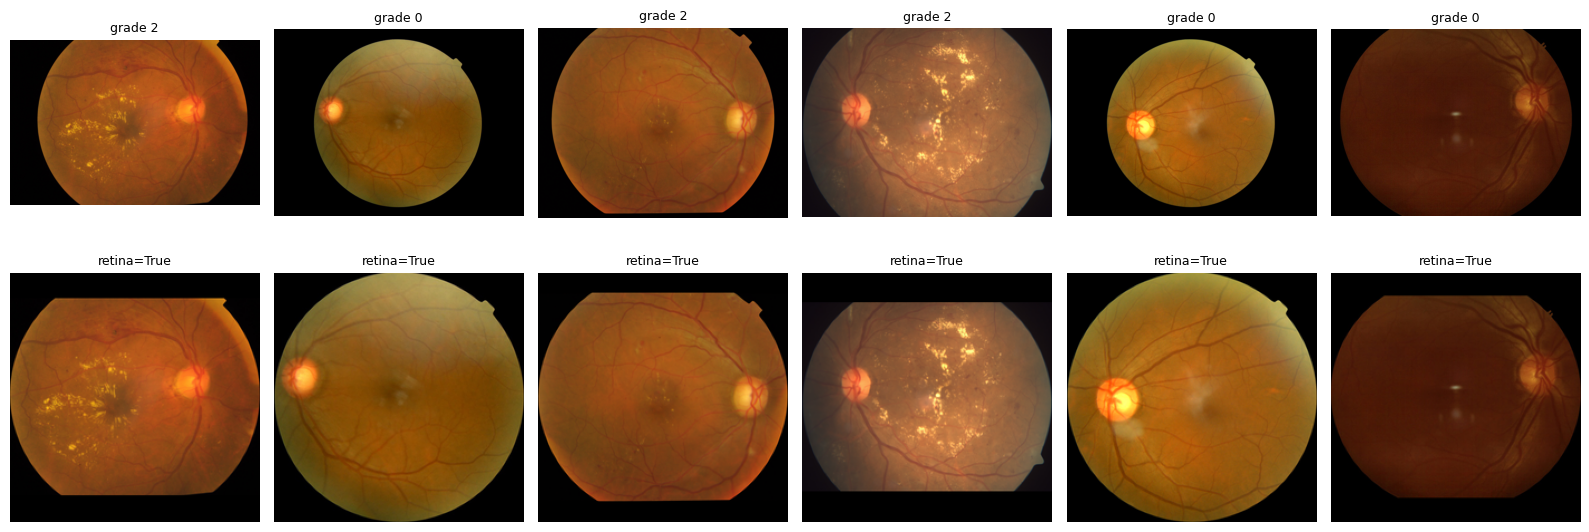

In [17]:
import matplotlib.pyplot as plt
sample = splits.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for k, (_, r) in enumerate(sample.iterrows()):
    with Image.open(r["path"]) as im:
        out, found = pp.preprocess_image(im, 224)
        axes[0, k].imshow(im); axes[0, k].set_title(f"grade {r['label']}", fontsize=9)
    axes[1, k].imshow(out); axes[1, k].set_title(f"retina={found}", fontsize=9)
    for a in axes[:, k]: a.axis("off")
plt.tight_layout(); plt.show()

In [18]:
from tqdm.auto import tqdm

not_found = [r["path"] for _, r in tqdm(splits.iterrows(), total=len(splits))
             if not pp.load_and_preprocess(r["path"], 224)[1]]
print(f"retina not found: {len(not_found)} of {len(splits)} images")

  0%|          | 0/3477 [00:00<?, ?it/s]

retina not found: 0 of 3477 images


### Preprocessed Cache

Applies `preprocess.py` once to every image and saves the result at the model
input size. Since preprocessing is deterministic, recomputing it every epoch
would only waste CPU time and leave the GPU waiting. The cache lives on the
Colab local disk, one folder
per input size.

In [16]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def build_cache(df, size):
    """Preprocesses every image to size x size and returns df with a cache_path column."""
    cache_dir = DATA / f"cache_{size}"
    out = [str(cache_dir / f"{s}_{Path(p).stem}.png") for s, p in zip(df["source"], df["path"])]
    if cache_dir.exists() and all(Path(p).exists() for p in out):
        print(f"[cache] reusing {cache_dir}")
        return df.assign(cache_path=out)

    cache_dir.mkdir(parents=True, exist_ok=True)
    def work(args):
        src, dst = args
        im, found = pp.load_and_preprocess(src, size)
        im.save(dst, compress_level=1)   # low compression = faster to write and read
        return found

    with ThreadPoolExecutor(8) as ex:
        found = list(tqdm(ex.map(work, zip(df["path"], out)), total=len(df), desc=f"cache {size}px"))
    print(f"{len(found)} images cached in {cache_dir} | retina not found: {len(found) - sum(found)}")
    return df.assign(cache_path=out)

splits = build_cache(splits, CFG["img_size"])
splits.head()

cache 384px:   0%|          | 0/3477 [00:00<?, ?it/s]

3477 images cached in /content/data/cache_384 | retina not found: 0


,path,label,source,md5,phash_hex,split,cache_path
2018,/content/data/aptos/train_images/936299166bea.png,0,aptos,9d0664f1255b5f444e32ae4cdf4815a5,95c14a972fda5a68,train,/content/data/cache_384/aptos_936299166bea.png
325,/content/data/aptos/train_images/18b06f56ab27.png,1,aptos,bb9726a009ef112d3991111efaf0026f,d5b500c91fb51fc2,train,/content/data/cache_384/aptos_18b06f56ab27.png
1981,/content/data/aptos/train_images/90a786abe58e.png,0,aptos,d70982d0d7ac54a000ac364900bd6585,94c94b943e4b6b3c,train,/content/data/cache_384/aptos_90a786abe58e.png
477,/content/data/aptos/train_images/22ce8ef69357.png,2,aptos,c3485540a4901a78a8c93ab125827db0,954b4ab5254a73b5,train,/content/data/cache_384/aptos_22ce8ef69357.png
1502,/content/data/aptos/train_images/6d6be4cfc73f.png,0,aptos,5b806afa0634dd5d55ac6a484a3a2035,90994fcd3a1a6c6d,train,/content/data/cache_384/aptos_6d6be4cfc73f.png


## Augmentation

Reads the preprocessed cache and builds the train/val/test datasets.
Augmentation is applied to the training set only, on the fly, so the model
sees a different variation of each image every epoch.

| Transform | Range | Rationale |
|---|---|---|
| Horizontal and vertical flip | random | DR grade doesn't depend on orientation |
| Rotation | any angle | same; real photos also come slightly rotated |
| Zoom | ±10% | small framing differences; more would cut the retina periphery |
| Brightness | ±10% | different cameras and illumination |

Excluded on purpose: hue shifts (color carries clinical information:
hemorrhages are red, exudates yellowish), blur (erases microaneurysms) and
cutout (may remove the very lesion that defines the grade).

In [17]:
import keras

AUTOTUNE = tf.data.AUTOTUNE

geometric_aug = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    keras.layers.RandomRotation(0.5, fill_mode="constant", fill_value=0.0, seed=SEED),   # any angle (±180°)
    keras.layers.RandomZoom((-0.1, 0.1), fill_mode="constant", fill_value=0.0, seed=SEED),
], name="geometric_aug")

def brightness_jitter(img, brightness=0.1):
    """Multiplicative brightness change: the black background stays black (0 x factor = 0)."""
    b = tf.random.uniform([], 1 - brightness, 1 + brightness)
    return tf.clip_by_value(img * b, 0.0, 255.0)

def load_image(path, label):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    return img, label

def augment(img, label):
    img = tf.cast(img, tf.float32)
    img = geometric_aug(img[tf.newaxis], training=True)[0]
    return brightness_jitter(img), label

def to_float(img, label):
    return tf.cast(img, tf.float32), label

def make_dataset(df, training):
    ds = tf.data.Dataset.from_tensor_slices((df["cache_path"].values, df["label"].values.astype("int32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()   # decoded images kept in RAM
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(to_float, num_parallel_calls=AUTOTUNE)
    return ds.batch(CFG["batch"]).prefetch(AUTOTUNE)

train_ds = make_dataset(splits[splits["split"] == "train"], training=True)
val_ds   = make_dataset(splits[splits["split"] == "val"],   training=False)
test_ds  = make_dataset(splits[splits["split"] == "test"],  training=False)

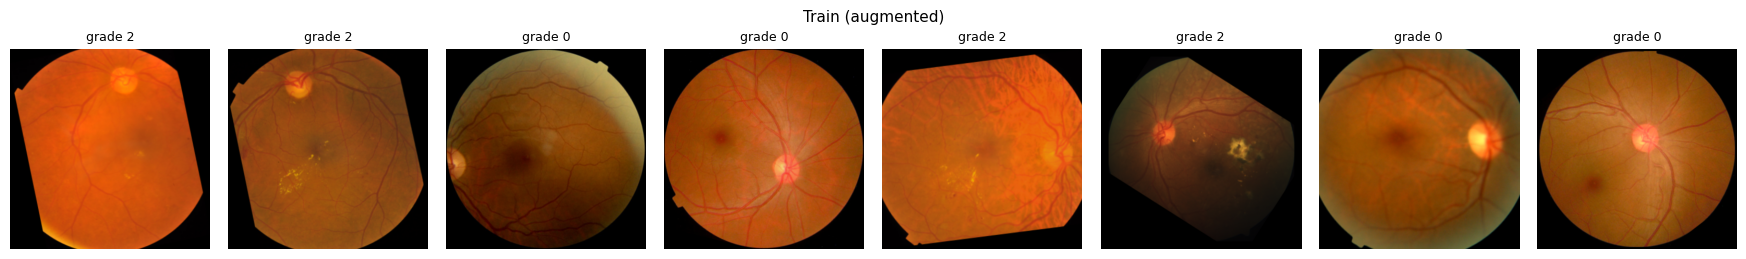

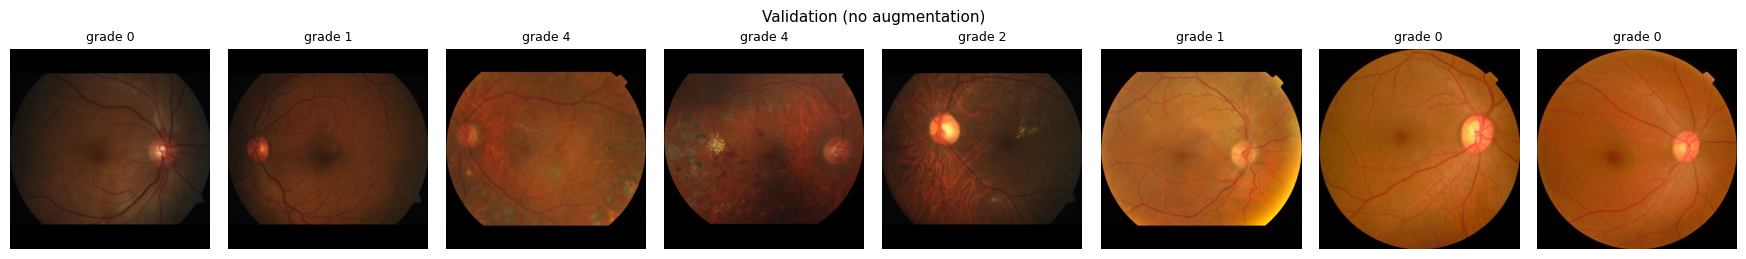

In [18]:
import matplotlib.pyplot as plt

def show_batch(ds, title, n=8):
    x, y = next(iter(ds))
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.6))
    for k, ax in enumerate(axes):
        ax.imshow(x[k].numpy().astype("uint8"))
        ax.set_title(f"grade {int(y[k])}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()

show_batch(train_ds, "Train (augmented)")
show_batch(val_ds, "Validation (no augmentation)")

### Class Weights

Grade 0 is about half of APTOS, so with an unweighted loss the model can reach decent accuracy by favoring it while ignoring grades 3 and 4, the clinically most important ones. **Weighted cross-entropy** multiplies each image's loss by the weight of its class:

$$
\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} w_{y_i} \log p_{i,\,y_i}
$$

where $N$ is the number of images, $y_i$ the true grade of image $i$, $p_{i,\,y_i}$ the probability the model assigns to that grade, and $w_{y_i}$ the weight of that grade.

**Balanced weights** (inverse class frequency), with $K = 5$ classes and $n_c$ training images in class $c$:

$$
w_c^{\text{bal}} = \frac{N}{K \cdot n_c}
$$

Every class gets the same total weight ($n_c \cdot w_c^{\text{bal}} = N/K$), but a grade 3 image weighs about 9 times a grade 0 image, which amplifies label noise in the rare classes.

**Square-root weights** (used here), a smoothed variant normalized so that the mean weight per image is 1:

$$
w_c^{\text{sqrt}} = \sqrt{w_c^{\text{bal}}} \cdot \frac{N}{\sum_{k=1}^{K} n_k \sqrt{w_k^{\text{bal}}}}
$$

The square root keeps the priority on rare classes with a ratio of about 3x instead of 9x. The normalization keeps the loss on the same scale as an unweighted run, so the learning rate stays comparable.

Weights are computed on the training split only; validation and test are
evaluated without weights, reflecting the real class distribution.

> References: King & Zeng (2001), *Logistic Regression in Rare Events Data*; Cui et al. (2019), *Class-Balanced Loss Based on Effective Number of Samples*.

In [19]:
from sklearn.utils.class_weight import compute_class_weight

NUM_CLASSES = 5
train_labels = splits.loc[splits["split"] == "train", "label"].to_numpy()
counts = np.bincount(train_labels, minlength=NUM_CLASSES)

balanced = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_labels)
sqrt_w = np.sqrt(balanced)
sqrt_w = sqrt_w * len(train_labels) / (sqrt_w * counts).sum()   # mean weight per image = 1

weights = {"balanced": balanced, "sqrt": sqrt_w, "none": np.ones(NUM_CLASSES)}[CFG["class_weight"]]
CLASS_WEIGHT = {c: float(w) for c, w in enumerate(weights)}

pd.DataFrame({
    "train images": counts,
    "balanced": balanced.round(2),
    "sqrt (normalized)": sqrt_w.round(2),
    "total weight (sqrt)": (counts * sqrt_w).round(0).astype(int),
}, index=pd.Index(range(NUM_CLASSES), name="grade"))

,train images,balanced,sqrt (normalized),total weight (sqrt)
grade,,,,
0,1249,0.39,0.68,855
1,237,2.05,1.57,372
2,644,0.76,0.95,614
3,118,4.12,2.23,263
4,185,2.63,1.78,329


## Model

Two pretrained ImageNet backbones, chosen to sit at opposite ends of the accuracy vs. efficiency trade-off:

| | ResNet-50 | MobileNetV2 |
|---|---|---|
| Key idea | Residual blocks (`F(x) + x`) enable very deep networks | Depthwise separable convolutions and inverted residuals cut computation |
| Parameters | ~23.6M | ~2.3M |
| Cost (224×224) | ~4 GFLOPs | ~0.3 GFLOPs |
| Role | Accuracy reference; thesis baseline, standard in DR literature | Edge model; designed for embedded devices, quantizes reliably to INT8 |

The comparison measures how much accuracy is lost for the latency, memory and size gained on the Pi. EfficientNet was not used because its original version loses significant accuracy under INT8 quantization.

Both start from ImageNet weights (transfer learning): with ~2,400 training images, training millions of parameters from scratch would overfit.

### Normalization


Each backbone expects the input format used during its ImageNet pretraining:

| | ResNet-50 | MobileNetV2 |
|---|---|---|
| Origin of weights | Original Caffe implementation | TensorFlow (Google) |
| Channel order | BGR | RGB |
| Scaling | Subtract per-channel ImageNet mean | Scale to [-1, 1] |

Feeding the wrong format would push first-layer activations outside the range the pretrained filters learned (or swap red and blue, critical in red-dominated fundus images), wasting most of the transfer learning benefit.
Normalization is the first layer of each model, so every `.tflite` prepares its own input and the Pi feeds the same raw image to either model.

In [20]:
import keras
from keras import layers

@keras.saving.register_keras_serializable(package="dr")
class CaffePreprocess(layers.Layer):
    """ResNet-50 normalization ("caffe"): RGB -> BGR and per-channel ImageNet mean subtraction.
    Same as keras.applications.resnet50.preprocess_input, but as a serializable layer."""
    MEAN_BGR = (103.939, 116.779, 123.68)

    def call(self, x):
        x = keras.ops.flip(x, axis=-1)   # RGB -> BGR
        return x - keras.ops.convert_to_tensor(self.MEAN_BGR, dtype=x.dtype)

def mobilenet_preprocess():
    """MobileNetV2 normalization: scales 0-255 to [-1, 1]."""
    return layers.Rescaling(1.0 / 127.5, offset=-1.0, name="mobilenet_preprocess")

### Architecture and training phases



`image (0-255) → normalization → backbone → global average pooling → dropout (0.3) → dense softmax (5 grades)`

| Choice | Rationale |
|---|---|
| Global average pooling | Collapses the backbone feature maps into one vector, with no extra parameters |
| Dropout 0.3 | Randomly drops 30% of features during training, reducing overfitting on a small dataset |
| Softmax over 5 grades | One probability per ICDR grade; the binary referable view is derived from these |
| BatchNormalization in inference mode | Keeps BN statistics fixed even after unfreezing; updating them with small batches tends to destabilize fine-tuning |

- **Phase 1:** backbone frozen, only the new head is trained.
- **Phase 2:** the top of the backbone is unfrozen (ResNet-50: `conv5`; MobileNetV2: blocks 14–16), with BN layers kept frozen. Early layers detect generic edges and textures; the last ones are the most ImageNet-specific and benefit most from adapting to fundus images.

In [21]:
NUM_CLASSES = 5
DROPOUT = 0.3

BACKBONES = {
    # name: (backbone constructor, normalization layer, layers unfrozen in phase 2)
    "resnet50": (keras.applications.ResNet50,
                 lambda: CaffePreprocess(name="resnet_preprocess"),
                 ("conv5_",)),
    "mobilenetv2": (keras.applications.MobileNetV2,
                    mobilenet_preprocess,
                    ("block_14", "block_15", "block_16", "Conv_1")),
}

### Model builder


**`build_model(name, img_size)`** assembles the model for the backbone selected in `CFG["model"]`, following the structure described above:

1. **Input**: RGB image in 0–255, shape `(img_size, img_size, 3)`, exactly as produced by the `tf.data` pipeline.
2. **Normalization**: the layer associated with the backbone in `BACKBONES`.
3. **Backbone**: loaded with ImageNet weights and without its original 1,000-class head (`include_top=False`). It starts frozen (`base.trainable = False`) and is always called with `training=False`, so BatchNormalization uses the stored statistics in both phases.
4. **Head**: global average pooling → dropout (`DROPOUT`) → dense softmax with `NUM_CLASSES` outputs.

It returns **`(model, base)`**. The backbone is returned separately because phase 2 needs direct access to its layers in order to unfreeze them.

**`unfreeze_top(base, name)`** prepares phase 2:

- sets the backbone as trainable, then goes layer by layer;
- keeps trainable only the layers whose names start with the prefixes listed in `BACKBONES` for that architecture (ResNet-50: `conv5_`; MobileNetV2: `block_14` to `block_16` and `Conv_1`);
- keeps every BatchNormalization layer frozen, even inside the unfrozen blocks, so its scale and shift parameters don't drift with small batches;
- prints how many backbone layers became trainable, as a quick check.

In [22]:
def build_model(name, img_size):
    """normalization -> pretrained backbone (frozen) -> pooling -> dropout -> softmax.
    Returns (model, base). BatchNormalization always runs in inference mode (training=False)."""
    backbone_fn, preprocess_fn, _ = BACKBONES[name]
    inputs = keras.Input((img_size, img_size, 3), name="image")
    x = preprocess_fn()(inputs)
    base = backbone_fn(include_top=False, weights="imagenet", input_shape=(img_size, img_size, 3))
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
    x = layers.Dropout(DROPOUT, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="grade")(x)
    return keras.Model(inputs, outputs, name=f"{name}_dr"), base

def unfreeze_top(base, name):
    """Phase 2: unfreezes only the top blocks of the backbone. BatchNormalization stays frozen."""
    prefixes = BACKBONES[name][2]
    base.trainable = True
    for layer in base.layers:
        layer.trainable = layer.name.startswith(prefixes) and not isinstance(layer, layers.BatchNormalization)
    print(f"{name}: {sum(l.trainable for l in base.layers)} of {len(base.layers)} backbone layers trainable")

In [24]:
model, base = build_model(CFG["model"], CFG["img_size"])
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"{model.name}: {model.count_params():,} parameters | {trainable:,} trainable in phase 1")

x, y = next(iter(val_ds))
p = model(x, training=False).numpy()
print("output:", p.shape, "| rows sum to 1:", np.allclose(p.sum(axis=1), 1, atol=1e-5))

/tmp/ipykernel_4137/2316236099.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = backbone_fn(include_top=False, weights="imagenet", input_shape=(img_size, img_size, 3))


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
mobilenetv2_dr: 2,264,389 parameters | 6,405 trainable in phase 1
output: (32, 5) | rows sum to 1: True


In [48]:
x_test = np.random.default_rng(0).uniform(0, 255, (2, 224, 224, 3)).astype("float32")
print("ResNet-50 normalization matches Keras:",
      np.allclose(CaffePreprocess()(x_test).numpy(),
                  keras.applications.resnet50.preprocess_input(x_test.copy()), atol=1e-4))

ResNet-50 normalization matches Keras: True


## Training

Two-phase transfer learning, with model selection by validation QWK (the standard metric for ordinal 5-grade DR classification). Each run gets its own folder on Drive with the config, best weights, final model, training history and curves, so experiments never overwrite each other.

### Run Setup

In [25]:
import json
from datetime import datetime

RUN_NAME = f"{CFG['model']}_{CFG['data']}_{CFG['img_size']}_{datetime.now():%Y%m%d_%H%M}"
RUN_DIR = DRIVE / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

with open(RUN_DIR / "config.json", "w") as f:
    json.dump({**CFG, "class_weight_values": CLASS_WEIGHT}, f, indent=2)
print("run dir:", RUN_DIR)

run dir: /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_2033


### Callbacks

**QWK (quadratic weighted kappa)** measures agreement between predicted and
true grades, discounting agreement expected by chance and penalizing errors by the squared distance between grades:

$$
\kappa = 1 - \frac{\sum_{i,j} w_{ij}\, O_{ij}}{\sum_{i,j} w_{ij}\, E_{ij}}, \qquad w_{ij} = \frac{(i-j)^2}{(K-1)^2}
$$

where $O$ is the confusion matrix and $E$ the matrix expected by chance.
Predicting grade 0 for a grade 4 case costs 16 times more than predicting
grade 3, and a model that always predicts the majority grade scores 0
(while still reaching ~50% accuracy). It ranges from -1 to 1 and is the
standard metric for 5-grade DR classification, so it is used for model selection.

- **QWK callback**: Keras has no built-in QWK, so it is computed on the
  validation set after every epoch and added to the logs as `val_qwk`.
  It must come first in the list, since the others monitor it.
- **Checkpoint**: saves the weights whenever `val_qwk` improves. The same
  callback is reused in both phases, so phase 2 only saves if it beats the
  best of phase 1.
- **Early stopping**: stops if `val_qwk` doesn't improve for 5 epochs.
- **Learning rate reduction**: halves the learning rate after 2 epochs
  without improvement.

QWK may be 0 in the first epochs: that happens when the model still predicts
a single grade for every image.

In [26]:
from sklearn.metrics import cohen_kappa_score

class QWKCallback(keras.callbacks.Callback):
    """Computes quadratic weighted kappa on the validation set at the end of every epoch
    and adds it to the logs as 'val_qwk', so checkpoint/early stopping can monitor it."""
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds
        self.y_true = np.concatenate([y.numpy() for _, y in val_ds])

    def on_epoch_end(self, epoch, logs=None):
        y_pred = self.model.predict(self.val_ds, verbose=0).argmax(axis=1)
        logs["val_qwk"] = cohen_kappa_score(self.y_true, y_pred, weights="quadratic")
        print(f" - val_qwk: {logs['val_qwk']:.4f}")

BEST_WEIGHTS = RUN_DIR / "best.weights.h5"
callbacks = [
    QWKCallback(val_ds),   # must come first: the callbacks below read 'val_qwk'
    keras.callbacks.ModelCheckpoint(BEST_WEIGHTS, monitor="val_qwk", mode="max",
                                    save_best_only=True, save_weights_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_qwk", mode="max", patience=5, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_qwk", mode="max", factor=0.5, patience=2,
                                      min_lr=1e-7, verbose=1),
]

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

### Phase 1: Head

In [56]:
compile_model(model, CFG["lr_head"])
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=CFG["epochs_head"], class_weight=CLASS_WEIGHT, callbacks=callbacks)

Epoch 1/5
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 782ms/step - accuracy: 0.4525 - loss: 1.6504 - val_qwk: 0.6918

Epoch 1: val_qwk improved from None to 0.69178, saving model to /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_1859/best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_1859/best.weights.h5
77/77 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.5582 - loss: 1.3564 - val_accuracy: 0.7203 - val_loss: 0.7755 - val_qwk: 0.6918 - learning_rate: 0.0010
Epoch 2/5
76/77 ━━━━━━━━━━━━━━━━━━━━ 0s 792ms/step - accuracy: 0.6793 - loss: 1.0729 - val_qwk: 0.8220

Epoch 2: val_qwk improved from 0.69178 to 0.82197, saving model to /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_1859/best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_1859/best.weights.h5
77/77 ━━━━━━━━━━━━━━━━━━━━ 64s 835ms/step - accuracy: 0.6930 - loss: 1.0284 - val_accuracy: 0.7682

### Phase 2: Fine-tuning

In [57]:
unfreeze_top(base, CFG["model"])
compile_model(model, CFG["lr_ft"])   # recompiling is what makes the unfreezing take effect
n_trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"trainable parameters in phase 2: {n_trainable:,}")

hist2 = model.fit(train_ds, validation_data=val_ds,
                  initial_epoch=len(hist1.epoch), epochs=len(hist1.epoch) + CFG["epochs_ft"],
                  class_weight=CLASS_WEIGHT, callbacks=callbacks)

mobilenetv2: 18 of 154 backbone layers trainable
trainable parameters in phase 2: 1,517,125
Epoch 6/35
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 860ms/step - accuracy: 0.6704 - loss: 1.0879 - val_qwk: 0.8515

Epoch 6: val_qwk improved from 0.83447 to 0.85155, saving model to /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_1859/best.weights.h5

Epoch 6: finished saving model to /content/drive/MyDrive/tcc/runs/mobilenetv2_aptos_384_20261005_1859/best.weights.h5
77/77 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.7041 - loss: 1.0046 - val_accuracy: 0.7701 - val_loss: 0.6412 - val_qwk: 0.8515 - learning_rate: 1.0000e-04
Epoch 7/35
76/77 ━━━━━━━━━━━━━━━━━━━━ 0s 807ms/step - accuracy: 0.7648 - loss: 0.8170 - val_qwk: 0.8270

Epoch 7: val_qwk did not improve from 0.85155
77/77 ━━━━━━━━━━━━━━━━━━━━ 64s 830ms/step - accuracy: 0.7460 - loss: 0.8521 - val_accuracy: 0.7375 - val_loss: 0.6301 - val_qwk: 0.8270 - learning_rate: 1.0000e-04
Epoch 8/35
76/77 ━━━━━━━━━━━━━━━━━━━━ 0s 798ms/step - ac

### History and Best Model

In [58]:
h1, h2 = pd.DataFrame(hist1.history), pd.DataFrame(hist2.history)
history = pd.concat([h1.assign(phase=1), h2.assign(phase=2)], ignore_index=True)
history.insert(0, "epoch", range(1, len(history) + 1))
history.to_csv(RUN_DIR / "history.csv", index=False)

# fresh model + best weights -> saved without optimizer state
best_model, _ = build_model(CFG["model"], CFG["img_size"])
best_model.load_weights(BEST_WEIGHTS)
best_model.save(RUN_DIR / "best_model.keras")

best = history.loc[history["val_qwk"].idxmax()]
print(f"best val_qwk: {best['val_qwk']:.4f} at epoch {int(best['epoch'])} (phase {int(best['phase'])})")

/tmp/ipykernel_547/2316236099.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = backbone_fn(include_top=False, weights="imagenet", input_shape=(img_size, img_size, 3))


best val_qwk: 0.8849 at epoch 15 (phase 2)


### Training Curves

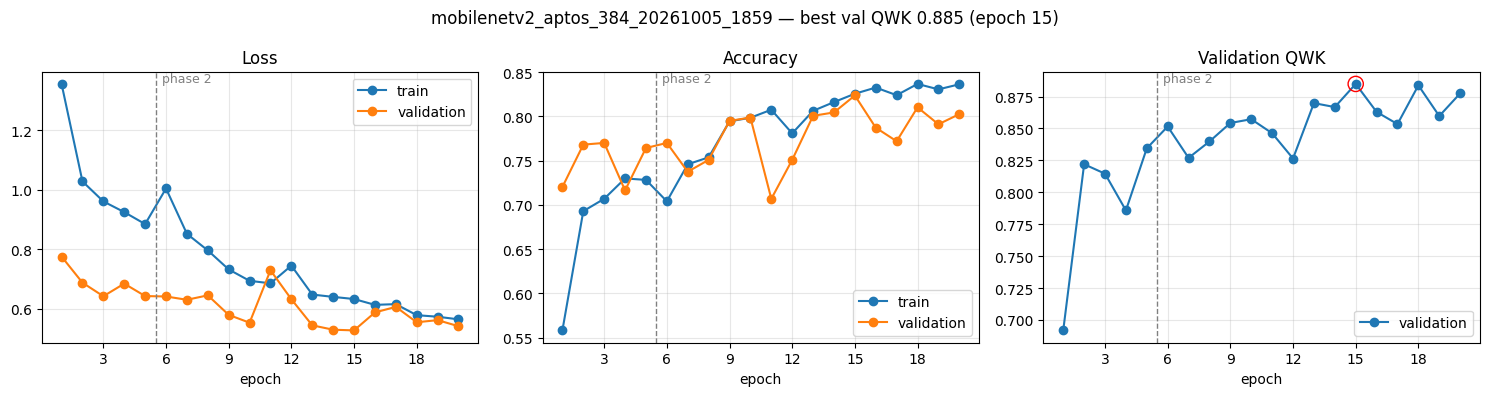

In [59]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
panels = [("loss", "val_loss", "Loss"), ("accuracy", "val_accuracy", "Accuracy"), (None, "val_qwk", "Validation QWK")]
phase2_start = history.loc[history["phase"] == 2, "epoch"].min()
for ax, (train_col, val_col, title) in zip(axes, panels):
    if train_col:
        ax.plot(history["epoch"], history[train_col], "o-", label="train")
    ax.plot(history["epoch"], history[val_col], "o-", label="validation")
    ax.axvline(phase2_start - 0.5, color="gray", linestyle="--", linewidth=1)
    ax.text(phase2_start - 0.4, ax.get_ylim()[1], " phase 2", va="top", fontsize=9, color="gray")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[2].scatter(best["epoch"], best["val_qwk"], s=120, facecolors="none", edgecolors="red", zorder=5)
fig.suptitle(f"{RUN_NAME} — best val QWK {best['val_qwk']:.3f} (epoch {int(best['epoch'])})", fontsize=12)
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Evaluation

Final metrics on the held-out test set, used **once**: every choice (thresholds, referable cut-off) is fitted on validation and only applied to test.

- **5 grades:** accuracy, QWK, macro F1, recall per grade, confusion matrix.
- **Optimized thresholds:** instead of `argmax`, the expected grade (probability-weighted mean of 0–4) is cut by 4 thresholds fitted on validation to maximize QWK. It uses the order of the grades, needs no retraining, and costs nothing on the Pi.
- **Referable DR (grade ≥ 2):** P(referable) = P(2) + P(3) + P(4); AUC sensitivity and specificity, with the cut-off chosen on validation by Youden's J (sensitivity + specificity − 1).

Results are saved to each run folder (`metrics.json`, test predictions,
figures) and compared in `runs/test_summary.csv`.

### Metrics

In [27]:
from scipy.optimize import minimize
from sklearn.metrics import (accuracy_score, cohen_kappa_score, f1_score, recall_score,
                             confusion_matrix, roc_auc_score, roc_curve)

GRADES = np.arange(NUM_CLASSES)

def predict(model, df):
    """Class probabilities for the images in df, in df order."""
    ds = make_dataset(df, training=False)
    return model.predict(ds, verbose=0), df["label"].to_numpy()

def grade_metrics(y, pred):
    return {
        "accuracy": accuracy_score(y, pred),
        "qwk": cohen_kappa_score(y, pred, weights="quadratic"),
        "f1_macro": f1_score(y, pred, average="macro", labels=GRADES, zero_division=0),
        "recall_per_grade": recall_score(y, pred, average=None, labels=GRADES, zero_division=0).round(4).tolist(),
    }

def apply_thresholds(probs, thr):
    """Expected grade (probability-weighted mean of 0..4) cut by sorted thresholds."""
    expected = probs @ GRADES
    return np.digitize(expected, np.sort(thr))

def fit_thresholds(probs, y):
    """Thresholds that maximize QWK on validation data, starting from the natural cuts."""
    loss = lambda t: -cohen_kappa_score(y, apply_thresholds(probs, t), weights="quadratic")
    res = minimize(loss, x0=[0.5, 1.5, 2.5, 3.5], method="Nelder-Mead", options={"xatol": 1e-3, "maxiter": 2000})
    return np.sort(res.x)

def fit_referable_threshold(probs, y):
    """Referable = grade >= 2. Threshold on P(grade >= 2) maximizing Youden's J."""
    fpr, tpr, thr = roc_curve(y >= 2, probs[:, 2:].sum(axis=1))
    return float(thr[np.argmax(tpr - fpr)])

def referable_metrics(probs, y, thr):
    score, truth = probs[:, 2:].sum(axis=1), y >= 2
    pred = score >= thr
    tp, fn = (pred & truth).sum(), (~pred & truth).sum()
    tn, fp = (~pred & ~truth).sum(), (pred & ~truth).sum()
    return {"auc": roc_auc_score(truth, score), "threshold": thr,
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp)}

def evaluate_run(run_name):
    """Loads a run from Drive, fits thresholds on validation and reports everything on test."""
    run_dir = DRIVE / "runs" / run_name
    cfg = json.loads((run_dir / "config.json").read_text())
    if cfg["img_size"] != CFG["img_size"]:
        raise ValueError(f"run used {cfg['img_size']} px but the current cache is {CFG['img_size']} px")
    model = keras.models.load_model(run_dir / "best_model.keras")

    p_val, y_val = predict(model, splits[splits["split"] == "val"])
    p_test, y_test = predict(model, splits[splits["split"] == "test"])

    thr = fit_thresholds(p_val, y_val)
    ref_thr = fit_referable_threshold(p_val, y_val)
    results = {
        "run": run_name, "model": cfg["model"], "img_size": cfg["img_size"],
        "qwk_thresholds": thr.round(4).tolist(),
        "test_argmax": grade_metrics(y_test, p_test.argmax(axis=1)),
        "test_thresholds": grade_metrics(y_test, apply_thresholds(p_test, thr)),
        "test_referable": referable_metrics(p_test, y_test, ref_thr),
        "val_qwk_argmax": cohen_kappa_score(y_val, p_val.argmax(axis=1), weights="quadratic"),
        "val_qwk_thresholds": cohen_kappa_score(y_val, apply_thresholds(p_val, thr), weights="quadratic"),
    }
    with open(run_dir / "metrics.json", "w") as f:
        json.dump(results, f, indent=2, default=float)
    np.savez(run_dir / "test_predictions.npz", probs=p_test, y=y_test)
    return results, p_test, y_test

### Figures

In [28]:
import matplotlib.pyplot as plt

def plot_confusion(y, pred, title, path):
    cm = confusion_matrix(y, pred, labels=GRADES)
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in GRADES:
        for j in GRADES:
            ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "#222")
    ax.set_xticks(GRADES); ax.set_yticks(GRADES)
    ax.set_xlabel("predicted grade"); ax.set_ylabel("true grade"); ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.046, label="share of true grade")
    fig.tight_layout(); fig.savefig(path, dpi=150, bbox_inches="tight"); plt.show()

def plot_roc(probs, y, results, path):
    fpr, tpr, _ = roc_curve(y >= 2, probs[:, 2:].sum(axis=1))
    r = results["test_referable"]
    fig, ax = plt.subplots(figsize=(4.6, 4.4))
    ax.plot(fpr, tpr, label=f"AUC = {r['auc']:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    ax.scatter(1 - r["specificity"], r["sensitivity"], color="red", zorder=5,
               label=f"threshold (val): sens {r['sensitivity']:.2f}, spec {r['specificity']:.2f}")
    ax.set_xlabel("1 - specificity"); ax.set_ylabel("sensitivity")
    ax.set_title(f"{results['model']} — referable DR (grade ≥ 2), test", fontsize=10)
    ax.legend(loc="lower right", fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(path, dpi=150, bbox_inches="tight"); plt.show()

### Run Evaluation

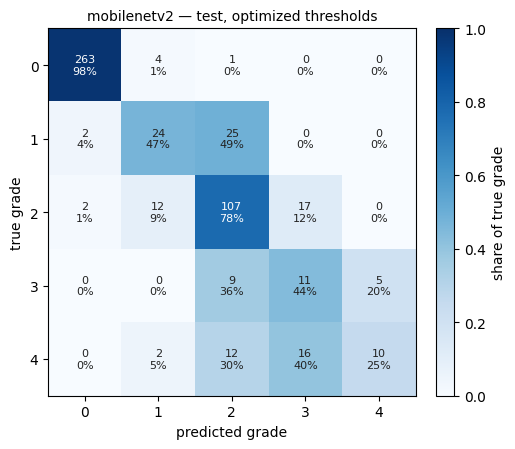

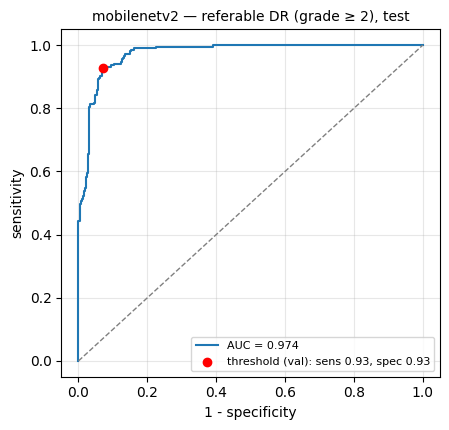

,model,px,QWK (argmax),QWK (thresholds),accuracy,F1 macro,AUC referable,sensitivity,specificity
0,mobilenetv2,384,0.869,0.895,0.795,0.583,0.974,0.926,0.928


In [64]:
import json
RUNS = ["mobilenetv2_aptos_384_20261005_1859"]

all_results = {}
for run_name in RUNS:
    res, p_test, y_test = evaluate_run(run_name)
    all_results[run_name] = res
    run_dir = DRIVE / "runs" / run_name
    plot_confusion(y_test, apply_thresholds(p_test, res["qwk_thresholds"]),
                   f"{res['model']} — test, optimized thresholds", run_dir / "confusion_test.png")
    plot_roc(p_test, y_test, res, run_dir / "roc_referable_test.png")

rows = []
for name, r in all_results.items():
    rows.append({"model": r["model"], "px": r["img_size"],
                 "QWK (argmax)": r["test_argmax"]["qwk"], "QWK (thresholds)": r["test_thresholds"]["qwk"],
                 "accuracy": r["test_thresholds"]["accuracy"], "F1 macro": r["test_thresholds"]["f1_macro"],
                 "AUC referable": r["test_referable"]["auc"],
                 "sensitivity": r["test_referable"]["sensitivity"], "specificity": r["test_referable"]["specificity"]})
summary = pd.DataFrame(rows).round(3)
summary.to_csv(DRIVE / "runs" / "test_summary.csv", index=False)
summary

## TFLite Conversion

Each trained model is converted to three precisions and re-evaluated on the
test set, measuring how much each compression step costs in accuracy:

| Precision | Size | How |
|---|---|---|
| float32 | 1x | Reference, no compression |
| float16 | ~1/2 | Weights stored in 16 bits, near-lossless |
| INT8 | ~1/4 | Weights and activations as 8-bit integers; fastest on the Pi's CPU |

INT8 needs a **representative dataset**: 300 training images (no
augmentation) passed through the model so the converter learns the value
range of each layer. The INT8 model takes raw `uint8` pixels as input (the
normalization is already inside the model) and outputs float probabilities.

The thresholds and referable cut-off are the ones fitted on validation with
the original Keras model, so the test set is still not used for any choice.
Latency measured on Colab is meaningless for the Pi; speed is benchmarked on
the device itself.

In [29]:
!pip install -q ai-edge-litert

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 74.6 MB/s eta 0:00:00


In [30]:
import os, time
from ai_edge_litert.interpreter import Interpreter

N_CALIBRATION = 300

def representative_dataset(n=N_CALIBRATION):
    """Training images (no augmentation) used to calibrate INT8 ranges. n=None uses the whole train set."""
    train = splits[splits["split"] == "train"]
    df = train if n is None else train.sample(min(n, len(train)), random_state=SEED)
    def gen():
        for path in df["cache_path"]:
            img = tf.io.decode_png(tf.io.read_file(path), channels=3)
            yield [tf.cast(img, tf.float32)[tf.newaxis]]
    return gen

def convert(model, precision, n_calib=N_CALIBRATION):
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    if precision == "fp16":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.target_spec.supported_types = [tf.float16]
    elif precision == "dynamic":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]   # INT8 weights, float activations
    elif precision == "int8":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = representative_dataset(n_calib)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.uint8
        conv.inference_output_type = tf.float32
    return conv.convert()

def tflite_predict(tfl_path, df):
    """Runs a .tflite file over df, one image at a time, as the Pi will (same LiteRT runtime)."""
    it = Interpreter(model_path=str(tfl_path), num_threads=os.cpu_count())
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    probs = []
    for path in df["cache_path"]:
        img = tf.io.decode_png(tf.io.read_file(path), channels=3).numpy()[np.newaxis]
        if inp["dtype"] == np.uint8:
            scale, zero = inp["quantization"]
            img = np.clip(np.round(img / scale + zero), 0, 255).astype(np.uint8)
        else:
            img = img.astype(np.float32)
        it.set_tensor(inp["index"], img)
        it.invoke()
        probs.append(it.get_tensor(out["index"])[0])
    return np.array(probs)

### Quantized Evaluation

In [31]:
VAL_RUNS = ["mobilenetv2_aptos_384_20261005_1859", "resnet50_aptos_384_20261005_1759"]

variants = {                     # tag: (precision, calibration images)
    "fp16":      ("fp16", None),
    "dynamic":   ("dynamic", None),
    "int8_c300": ("int8", 300),
    "int8_call": ("int8", None),
}

val_df = splits[splits["split"] == "val"]
y_val = val_df["label"].to_numpy()
qwk = lambda y, p: cohen_kappa_score(y, p, weights="quadratic")

rows = []
for run_name in VAL_RUNS:
    run_dir = DRIVE / "runs" / run_name
    cfg = json.loads((run_dir / "config.json").read_text())
    assert cfg["img_size"] == CFG["img_size"], f"{run_name} needs the {cfg['img_size']} px cache"
    model = keras.models.load_model(run_dir / "best_model.keras")
    p_keras = model.predict(make_dataset(val_df, training=False), verbose=0)
    rows.append({"model": cfg["model"], "variant": "keras (fp32)", "size (MB)": None,
                 "val QWK (argmax)": qwk(y_val, p_keras.argmax(1)),
                 "same grade as Keras": 1.0, "max prob. diff": 0.0})

    (run_dir / "tflite").mkdir(exist_ok=True)
    for tag, (precision, n) in variants.items():
        t0 = time.time()
        path = run_dir / "tflite" / f"{cfg['model']}_{cfg['img_size']}_{tag}.tflite"
        path.write_bytes(convert(model, precision, n))
        p = tflite_predict(path, val_df)
        rows.append({"model": cfg["model"], "variant": tag, "size (MB)": path.stat().st_size / 1e6,
                     "val QWK (argmax)": qwk(y_val, p.argmax(1)),
                     "same grade as Keras": (p.argmax(1) == p_keras.argmax(1)).mean(),
                     "max prob. diff": np.abs(p - p_keras).max()})
        print(f"{cfg['model']} {tag}: done in {time.time() - t0:.0f}s")

quant_val = pd.DataFrame(rows).round(3)
quant_val.to_csv(DRIVE / "runs" / "quantization_val_384.csv", index=False)
quant_val

Saved artifact at '/tmp/tmprn2lorkv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 384, 384, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132947868226512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868228240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868226320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868229200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868232848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868230928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868223440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868234576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868224016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868236496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868223248: Tens

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


mobilenetv2 int8_c300: done in 82s
Saved artifact at '/tmp/tmpzq2wrol1'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 384, 384, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132947868226512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868228240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868226320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868229200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868232848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868230928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868223440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868234576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868224016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947868236496: TensorSpec(shape=(), dtype=tf.resource,

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


mobilenetv2 int8_call: done in 448s
Saved artifact at '/tmp/tmpx6r30t0w'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 384, 384, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132947193437776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193437584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193439888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193439504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193439312: TensorSpec(shape=(), dtype=tf.resource

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


resnet50 int8_c300: done in 372s
Saved artifact at '/tmp/tmp_z4zdnlc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 384, 384, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132947193437776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193437584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193438928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193439888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193439504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132947193439312: TensorSpec(shape=(), dtype=tf.resource, n

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


resnet50 int8_call: done in 1987s


,model,variant,size (MB),val QWK (argmax),same grade as Keras,max prob. diff
0,mobilenetv2,keras (fp32),NaN,0.885,1.000,0.000
1,mobilenetv2,fp16,4.520,0.878,0.994,0.051
2,mobilenetv2,dynamic,2.536,0.855,0.941,0.444
3,mobilenetv2,int8_c300,2.739,0.840,0.916,0.398
4,mobilenetv2,int8_call,2.739,0.837,0.908,0.379
5,resnet50,keras (fp32),NaN,0.882,1.000,0.000
6,resnet50,fp16,47.068,0.882,1.000,0.006
7,resnet50,dynamic,23.947,0.884,0.994,0.151
8,resnet50,int8_c300,24.271,0.711,0.764,0.993
9,resnet50,int8_call,24.271,0.703,0.759,0.993


In [ ]:
PRECISIONS = ["fp32", "fp16", "int8"]
test_df = splits[splits["split"] == "test"]
y_test = test_df["label"].to_numpy()

rows = []
for run_name in RUNS:
    run_dir = DRIVE / "runs" / run_name
    metrics = json.loads((run_dir / "metrics.json").read_text())
    thr, ref_thr = metrics["qwk_thresholds"], metrics["test_referable"]["threshold"]
    model = keras.models.load_model(run_dir / "best_model.keras")
    p_keras = model.predict(make_dataset(test_df, training=False), verbose=0)
    (run_dir / "tflite").mkdir(exist_ok=True)

    for precision in PRECISIONS:
        tfl_path = run_dir / "tflite" / f"{metrics['model']}_{metrics['img_size']}_{precision}.tflite"
        t0 = time.time()
        tfl_path.write_bytes(convert(model, precision))
        p = tflite_predict(tfl_path, test_df)
        ref = referable_metrics(p, y_test, ref_thr)
        rows.append({
            "model": metrics["model"], "precision": precision,
            "size (MB)": tfl_path.stat().st_size / 1e6,
            "QWK (argmax)": cohen_kappa_score(y_test, p.argmax(1), weights="quadratic"),
            "QWK (thresholds)": cohen_kappa_score(y_test, apply_thresholds(p, thr), weights="quadratic"),
            "accuracy (argmax)": accuracy_score(y_test, p.argmax(1)),
            "AUC referable": ref["auc"], "sensitivity": ref["sensitivity"], "specificity": ref["specificity"],
            "same grade as Keras": (p.argmax(1) == p_keras.argmax(1)).mean(),
            "max prob. diff vs Keras": np.abs(p - p_keras).max(),
        })
        print(f"{run_name} {precision}: {rows[-1]['size (MB)']:.1f} MB, done in {time.time() - t0:.0f}s")

quant = pd.DataFrame(rows).round(3)
quant.to_csv(DRIVE / "runs" / "quantization_summary.csv", index=False)
quant

### Quantized Test Evaluation

The TFLite variants chosen on validation (`quantization_val_384.csv`) are
evaluated once on the test set, with the thresholds and referable cut-off
fitted on validation with the Keras model. The Keras row is the reference;
"same grade as Keras" measures what quantization changed.

In [32]:
BENCHMARK = {   # run -> TFLite variants that go to the Pi (chosen on validation)
    "mobilenetv2_aptos_384_20261005_1859": ["fp16", "int8_c300"],
    "resnet50_aptos_384_20261005_1759": ["dynamic"],
}

test_df = splits[splits["split"] == "test"]
y_test = test_df["label"].to_numpy()

def test_row(model_name, variant, p, thr, ref_thr, p_keras, size_mb=None):
    by_thr = grade_metrics(y_test, apply_thresholds(p, thr))
    ref = referable_metrics(p, y_test, ref_thr)
    return {"model": model_name, "variant": variant, "size (MB)": size_mb,
            "QWK (argmax)": cohen_kappa_score(y_test, p.argmax(1), weights="quadratic"),
            "QWK (thresholds)": by_thr["qwk"],
            "accuracy (argmax)": accuracy_score(y_test, p.argmax(1)),
            "accuracy (thresholds)": by_thr["accuracy"], "F1 macro (thresholds)": by_thr["f1_macro"],
            "AUC referable": ref["auc"], "sensitivity": ref["sensitivity"], "specificity": ref["specificity"],
            "same grade as Keras": (p.argmax(1) == p_keras.argmax(1)).mean()}

rows = []
for run_name, tags in BENCHMARK.items():
    run_dir = DRIVE / "runs" / run_name
    metrics = json.loads((run_dir / "metrics.json").read_text())
    assert metrics["img_size"] == CFG["img_size"], f"{run_name} needs the {metrics['img_size']} px cache"
    thr, ref_thr = metrics["qwk_thresholds"], metrics["test_referable"]["threshold"]   # both fitted on validation

    keras_test = np.load(run_dir / "test_predictions.npz")   # saved by evaluate_run
    assert np.array_equal(keras_test["y"], y_test), "test set order differs from evaluate_run"
    p_keras = keras_test["probs"]
    rows.append(test_row(metrics["model"], "keras (fp32)", p_keras, thr, ref_thr, p_keras))

    for tag in tags:
        path = run_dir / "tflite" / f"{metrics['model']}_{metrics['img_size']}_{tag}.tflite"
        t0 = time.time()
        p = tflite_predict(path, test_df)
        np.savez(path.with_suffix(".test.npz"), probs=p, y=y_test)
        rows.append(test_row(metrics["model"], tag, p, thr, ref_thr, p_keras, path.stat().st_size / 1e6))
        print(f"{metrics['model']} {tag}: done in {time.time() - t0:.0f}s")

quant_test = pd.DataFrame(rows).round(3)
quant_test.to_csv(DRIVE / "runs" / f"quantization_summary_{CFG['img_size']}.csv", index=False)
quant_test

mobilenetv2 fp16: done in 16s
mobilenetv2 int8_c300: done in 17s
resnet50 dynamic: done in 147s


,model,variant,size (MB),QWK (argmax),QWK (thresholds),accuracy (argmax),accuracy (thresholds),F1 macro (thresholds),AUC referable,sensitivity,specificity,same grade as Keras
0,mobilenetv2,keras (fp32),NaN,0.869,0.895,0.818,0.795,0.583,0.974,0.926,0.928,1.000
1,mobilenetv2,fp16,4.520,0.867,0.894,0.812,0.791,0.578,0.974,0.926,0.928,0.990
2,mobilenetv2,int8_c300,2.739,0.831,0.866,0.803,0.795,0.583,0.971,0.837,0.944,0.900
3,resnet50,keras (fp32),NaN,0.887,0.901,0.816,0.791,0.605,0.979,0.946,0.915,1.000
4,resnet50,dynamic,23.947,0.886,0.897,0.818,0.784,0.599,0.978,0.951,0.912,0.992


## Deploy Package

Everything the Raspberry Pi needs, in one folder: the benchmark candidates
(`.tflite`), `preprocess.py` (the same module used to build the training
cache) and `config.json` with image size, grade names, QWK thresholds and
referable cut-off per model. A parity check confirms that a raw image passed
through `preprocess.py` is pixel-identical to the cached image the models
were evaluated on. Sample raw test images are included for the file-mode demo.

In [33]:
import shutil
from datetime import datetime

SCRIPTS = Path("/content/drive/MyDrive/tcc/scripts")
GRADE_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]
DEFAULT_MODEL = "mobilenetv2_384_fp16"   # provisional: the Pi benchmark decides
SAMPLES_PER_GRADE = 2

DEPLOY = DRIVE / "deploy" / f"retinaedge_{CFG['img_size']}"
if DEPLOY.exists():
    shutil.rmtree(DEPLOY)
(DEPLOY / "models").mkdir(parents=True)
(DEPLOY / "samples").mkdir()
shutil.copy(SCRIPTS / "preprocess.py", DEPLOY)

# ---- models: .tflite + everything the Pi needs to reproduce the evaluation ----
test_by_variant = {(r["model"], r["variant"]): r for r in quant_test.to_dict("records")}
models = []
for run_name, tags in BENCHMARK.items():
    run_dir = DRIVE / "runs" / run_name
    metrics = json.loads((run_dir / "metrics.json").read_text())
    for tag in tags:
        name = f"{metrics['model']}_{metrics['img_size']}_{tag}"
        src = run_dir / "tflite" / f"{name}.tflite"
        shutil.copy(src, DEPLOY / "models")
        it = Interpreter(model_path=str(src)); it.allocate_tensors()
        inp = it.get_input_details()[0]
        t = test_by_variant[(metrics["model"], tag)]
        models.append({
            "name": name, "file": f"models/{name}.tflite", "run": run_name,
            "backbone": metrics["model"], "variant": tag,
            "input_dtype": np.dtype(inp["dtype"]).name,            # uint8 (int8) or float32
            "input_quantization": [float(v) for v in inp["quantization"]],
            "qwk_thresholds": metrics["qwk_thresholds"],
            "referable_threshold": metrics["test_referable"]["threshold"],
            "test": {k: t[k] for k in ["QWK (argmax)", "QWK (thresholds)", "accuracy (argmax)",
                                       "AUC referable", "sensitivity", "specificity"]},
        })

config = {
    "project": "RetinaEdge",
    "created": datetime.now().isoformat(timespec="seconds"),
    "img_size": CFG["img_size"],
    "input": "RGB uint8 (H, W, 3) from preprocess.load_and_preprocess + to_array; "
             "normalization is inside the model, feed raw 0-255 values",
    "grade_names": GRADE_NAMES,
    "referable_min_grade": 2,
    "grade_rule": "expected = probs @ [0..4]; grade = digitize(expected, qwk_thresholds)",
    "referable_rule": "P(referable) = probs[2:].sum() >= referable_threshold",
    "default_model": DEFAULT_MODEL,
    "models": models,
}
(DEPLOY / "config.json").write_text(json.dumps(config, indent=2, default=float))

# ---- sample images: raw test images (as the Pi will receive them), grade in the file name ----
test_df = splits[splits["split"] == "test"]
samples = (test_df.groupby("label", group_keys=False)
                  .apply(lambda g: g.sample(min(SAMPLES_PER_GRADE, len(g)), random_state=SEED)))
for _, r in samples.iterrows():
    shutil.copy(r["path"], DEPLOY / "samples" / f"grade{r['label']}_{Path(r['path']).name}")

# ---- parity check: raw image -> preprocess.py must equal the cache the models were evaluated on ----
for _, r in samples.iterrows():
    im, found = pp.load_and_preprocess(r["path"], CFG["img_size"])
    cached = tf.io.decode_png(tf.io.read_file(r["cache_path"]), channels=3).numpy()
    assert found and np.array_equal(pp.to_array(im), cached), f"preprocess mismatch: {r['path']}"
print(f"parity check OK on {len(samples)} raw images")

zip_path = shutil.make_archive(str(DEPLOY), "zip", DEPLOY)
for f in sorted(DEPLOY.rglob("*")):
    if f.is_file():
        print(f"{f.relative_to(DEPLOY)}  {f.stat().st_size / 1e6:.2f} MB")
print("zip:", zip_path)

/tmp/ipykernel_4137/2322917406.py:58: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(SAMPLES_PER_GRADE, len(g)), random_state=SEED)))


parity check OK on 10 raw images
config.json  0.00 MB
models/mobilenetv2_384_fp16.tflite  4.52 MB
models/mobilenetv2_384_int8_c300.tflite  2.74 MB
models/resnet50_384_dynamic.tflite  23.95 MB
preprocess.py  0.00 MB
samples/grade0_4982378d72f9.png  0.13 MB
samples/grade0_fa9f1bc03f21.png  0.31 MB
samples/grade1_194814669fee.png  0.19 MB
samples/grade1_2994f17f58a5.png  0.19 MB
samples/grade2_60e269e3e188.png  0.20 MB
samples/grade2_7e9458de5707.png  0.20 MB
samples/grade3_36b5b3c9fb32.png  0.24 MB
samples/grade3_42cc993f23a9.png  0.21 MB
samples/grade4_07122e268a1d.png  0.15 MB
samples/grade4_70d657f8f503.png  0.29 MB
zip: /content/drive/MyDrive/tcc/deploy/retinaedge_384.zip


### Quantization Figures

Three views of the same test results, built from the saved predictions
(no new inference):

1. **QWK per variant**, grouped by model, with the Keras fp32 score as a
   dashed reference line.
2. **Referable ROC, Keras vs TFLite**, with the cut-off fitted on validation
   marked on each curve. It separates two effects: how well the variant
   ranks cases (AUC, the curve) and whether the Keras cut-off still sits in
   the right place (the dot).
3. **Confusion matrices** of each variant next to the Keras one, with the
   optimized thresholds.

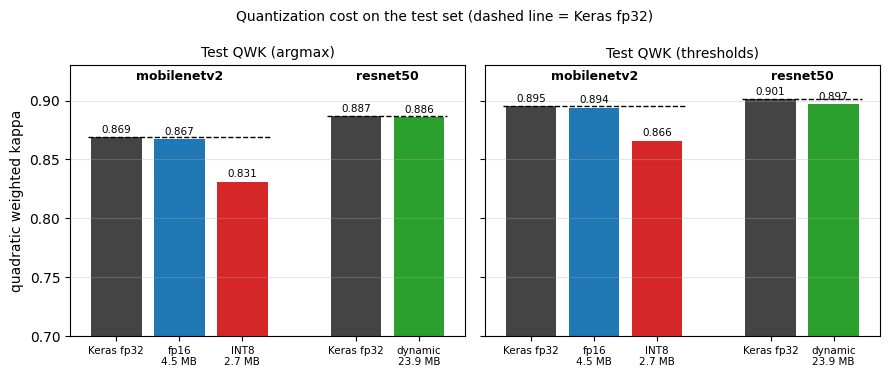

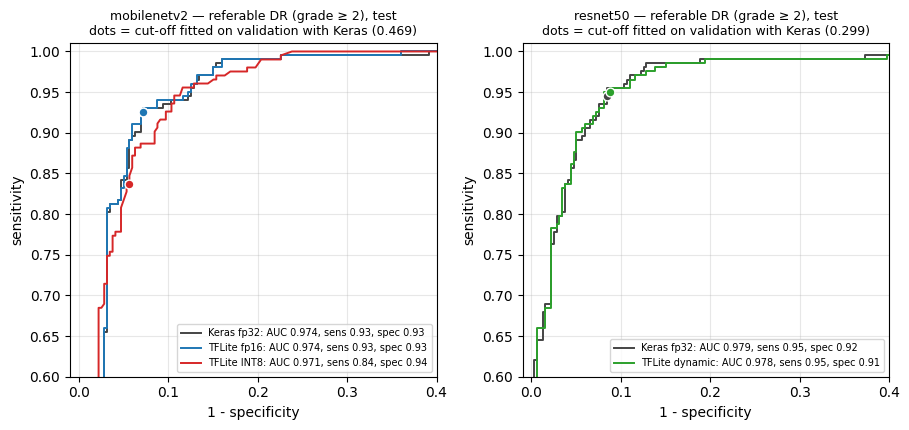

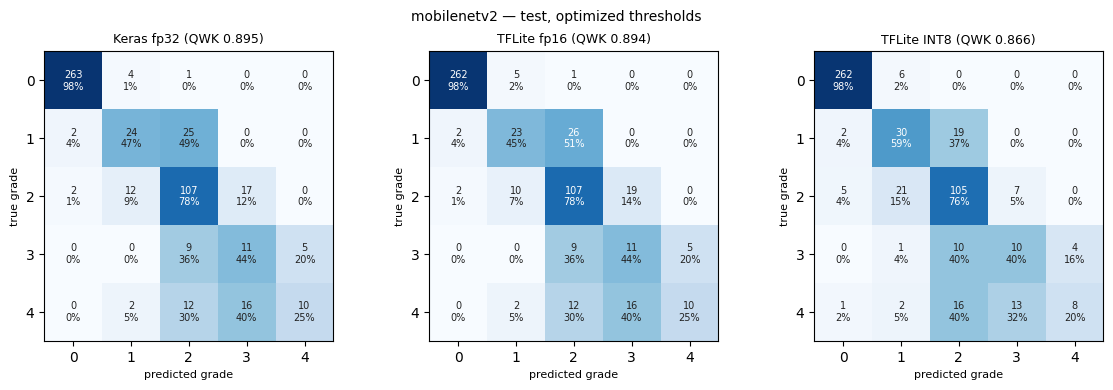

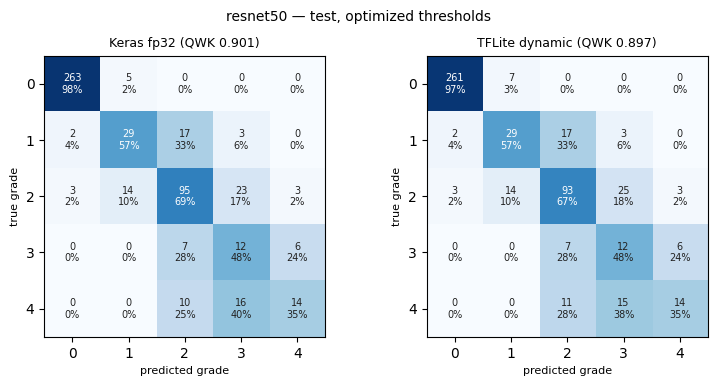

saved to /content/drive/MyDrive/tcc/runs/figures_quant_384 : ['confusion_mobilenetv2_quantized.png', 'confusion_resnet50_quantized.png', 'qwk_per_variant.png', 'roc_referable_quantized.png']


In [34]:
quant_test = pd.read_csv(DRIVE / "runs" / f"quantization_summary_{CFG['img_size']}.csv")
FIG_DIR = DRIVE / "runs" / f"figures_quant_{CFG['img_size']}"
FIG_DIR.mkdir(parents=True, exist_ok=True)
LABEL = {"keras (fp32)": "Keras fp32", "fp16": "TFLite fp16", "dynamic": "TFLite dynamic", "int8_c300": "TFLite INT8"}
COLOR = {"keras (fp32)": "#444444", "fp16": "#1f77b4", "dynamic": "#2ca02c", "int8_c300": "#d62728"}

def load_variants(run_name, tags):
    """Saved test probabilities (Keras + each TFLite variant) and the thresholds fitted on validation."""
    run_dir = DRIVE / "runs" / run_name
    metrics = json.loads((run_dir / "metrics.json").read_text())
    keras_test = np.load(run_dir / "test_predictions.npz")
    y = keras_test["y"]
    probs = {"keras (fp32)": keras_test["probs"]}
    for tag in tags:
        saved = np.load(run_dir / "tflite" / f"{metrics['model']}_{metrics['img_size']}_{tag}.test.npz")
        assert np.array_equal(saved["y"], y), f"{tag}: test order differs"
        probs[tag] = saved["probs"]
    return metrics, y, probs

# ---- Figure 1: QWK per variant, grouped by model ----
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, metric in zip(axes, ["QWK (argmax)", "QWK (thresholds)"]):
    models = list(dict.fromkeys(quant_test["model"]))
    x, ticks, labels = 0, [], []
    for m in models:
        sub = quant_test[quant_test["model"] == m]
        ref = sub.loc[sub["variant"] == "keras (fp32)", metric].item()
        start = x
        for _, r in sub.iterrows():
            ax.bar(x, r[metric], color=COLOR[r["variant"]], width=0.8)
            ax.text(x, r[metric] + 0.004, f"{r[metric]:.3f}", ha="center", fontsize=7.5)
            size = "" if pd.isna(r["size (MB)"]) else f"\n{r['size (MB)']:.1f} MB"
            ticks.append(x); labels.append(LABEL[r["variant"]].replace("TFLite ", "") + size)
            x += 1
        ax.hlines(ref, start - 0.45, x - 0.55, colors="black", linestyles="--", linewidth=1)
        ax.text((start + x - 1) / 2, 0.918, m, ha="center", fontsize=9, weight="bold")
        x += 0.8
    ax.set_xticks(ticks); ax.set_xticklabels(labels, fontsize=7.5)
    ax.set_ylim(0.7, 0.93); ax.set_title(f"Test {metric}", fontsize=10); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("quadratic weighted kappa")
fig.suptitle("Quantization cost on the test set (dashed line = Keras fp32)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "qwk_per_variant.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Figure 2: referable ROC, Keras vs TFLite, with the validation cut-off on each curve ----
fig, axes = plt.subplots(1, len(BENCHMARK), figsize=(4.6 * len(BENCHMARK), 4.4))
for ax, (run_name, tags) in zip(np.atleast_1d(axes), BENCHMARK.items()):
    metrics, y, probs = load_variants(run_name, tags)
    ref_thr = metrics["test_referable"]["threshold"]
    for variant, p in probs.items():
        score = p[:, 2:].sum(axis=1)
        fpr, tpr, _ = roc_curve(y >= 2, score)
        pred = score >= ref_thr
        sens, spec = (pred & (y >= 2)).sum() / (y >= 2).sum(), (~pred & (y < 2)).sum() / (y < 2).sum()
        ax.plot(fpr, tpr, color=COLOR[variant], linewidth=1.4,
                label=f"{LABEL[variant]}: AUC {roc_auc_score(y >= 2, score):.3f}, sens {sens:.2f}, spec {spec:.2f}")
        ax.scatter(1 - spec, sens, color=COLOR[variant], s=40, zorder=5, edgecolor="white")
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    ax.set_xlim(-0.01, 0.4); ax.set_ylim(0.6, 1.01)   # zoom on the region that matters
    ax.set_xlabel("1 - specificity"); ax.set_ylabel("sensitivity")
    ax.set_title(f"{metrics['model']} — referable DR (grade ≥ 2), test\n"
                 f"dots = cut-off fitted on validation with Keras ({ref_thr:.3f})", fontsize=9)
    ax.legend(loc="lower right", fontsize=7); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG_DIR / "roc_referable_quantized.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- Figure 3: confusion matrices, Keras vs each TFLite variant (optimized thresholds) ----
for run_name, tags in BENCHMARK.items():
    metrics, y, probs = load_variants(run_name, tags)
    fig, axes = plt.subplots(1, len(probs), figsize=(3.9 * len(probs), 3.8))
    for ax, (variant, p) in zip(np.atleast_1d(axes), probs.items()):
        pred = apply_thresholds(p, metrics["qwk_thresholds"])
        cm = confusion_matrix(y, pred, labels=GRADES)
        cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
        for i in GRADES:
            for j in GRADES:
                ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=7,
                        color="white" if cm_norm[i, j] > 0.5 else "#222")
        ax.set_xticks(GRADES); ax.set_yticks(GRADES)
        ax.set_xlabel("predicted grade", fontsize=8); ax.set_ylabel("true grade", fontsize=8)
        qwk_v = cohen_kappa_score(y, pred, weights="quadratic")
        ax.set_title(f"{LABEL[variant]} (QWK {qwk_v:.3f})", fontsize=9)
    fig.suptitle(f"{metrics['model']} — test, optimized thresholds", fontsize=10)
    fig.tight_layout(); fig.savefig(FIG_DIR / f"confusion_{metrics['model']}_quantized.png", dpi=150, bbox_inches="tight")
    plt.show()

print("saved to", FIG_DIR, ":", sorted(f.name for f in FIG_DIR.iterdir()))